**Introducción a la Ciencia de Datos 2026**
Posgrado en Ciencias de la Computación - CICESE
Dr. Irvin Hussein López Nava

## ICD - 14: Aprendizaje bayesiano

Sesión 14 del curso. Diapositivas: [icd-14-aprendizaje-bayesiano.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-14-aprendizaje-bayesiano.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-14-aprendizaje-bayesiano.ipynb)

En la sesión 13 abrimos la primera caja negra de la sesión 12, el árbol de decisión. Hoy abrimos la segunda: **Naive Bayes**. En clase vimos el teorema de Bayes, cómo elegir la hipótesis más probable (MAP) o la más verosímil (ML), el clasificador óptimo de Bayes y, al final, el clasificador Naive Bayes y las redes bayesianas.

El notebook tiene cuatro partes. En la primera aplicamos el teorema de Bayes a mano con el paciente de las diapositivas y leemos el resultado con las métricas de la sesión 12. En la segunda programamos Naive Bayes y reproducimos, cifra por cifra, el ejemplo de *Play tennis*. En la tercera pasamos los mismos días a scikit-learn, que tiene una clase de Naive Bayes para cada tipo de atributo, y vemos cómo se trata un atributo continuo. En la cuarta volvemos al vino de la sesión 12 con el protocolo del notebook 13: la suposición «ingenua» no se cumple, y medimos lo que eso cuesta.

---

### Preparación

Las bibliotecas de siempre. Las secciones 1 y 2 solo usan pandas, NumPy y la biblioteca estándar de Python; scikit-learn entra en la sección 3.

In [1]:
import math
import warnings
from collections import Counter
from itertools import permutations, product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sklearn

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", __import__("matplotlib").__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.5.3
pandas       3.0.5
matplotlib   3.11.2
scikit-learn 1.9.1


Paleta y estilo de las sesiones anteriores. El naranja sigue siendo lo que produce el modelo.

In [2]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
NARANJA = "#E76A28"      # lo que produce el modelo
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})

SEMILLA = 42                        # fija las particiones para que los resultados se repitan
CLASES = ["baja", "media", "alta"]  # el orden en que se muestran las clases del vino

---

### Los datos

Los mismos archivos del notebook 13:

- `weather.nominal.csv` es la tabla de *Play tennis* de la lámina 28 (Mitchell, 1997, tabla 3.2): 14 días y cuatro atributos con valores discretos.
- `weather.numeric.csv` tiene los mismos días, con la temperatura y la humedad medidas. Lo usamos en la sección 3.
- `vinos-3clases.csv` es el vino de 3 clases de la sesión 12. Lo usamos en la sección 4.

La sección 1 no usa datos: solo las cifras de la lámina 12.

En las tres lecturas, la primera línea funciona tal cual desde la carpeta del repositorio clonado. En Colab, comenta la primera y descomenta la segunda.

In [3]:
nominal = pd.read_csv("datos/weather.nominal.csv")
# nominal = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.nominal.csv")

numerico = pd.read_csv("datos/weather.numeric.csv")
# numerico = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.numeric.csv")

nominal

,Day,Outlook,Temperature,Humidity,Wind,Play
0,1,sunny,hot,high,weak,False
1,2,sunny,hot,high,strong,False
2,3,overcast,hot,high,weak,True
3,4,rain,mild,high,weak,True
4,5,rain,cool,normal,weak,True
5,6,rain,cool,normal,strong,False
6,7,overcast,cool,normal,strong,True
7,8,sunny,mild,high,weak,False
8,9,sunny,cool,normal,weak,True
9,10,rain,mild,normal,weak,True


**Lectura.** `Play` vale `True` en 9 días y `False` en 5; `True` es Yes. `Day` es un identificador, no un atributo (sesión 13), así que aquí no entra al modelo.

---

## 1. Bayes a mano: el paciente de la lámina 11

Un paciente se hace una prueba de laboratorio y sale positiva. La prueba detecta 98 % de los casos de cáncer y da negativo en 97 % de las personas sanas, y 0.8 % de la población tiene ese cáncer. ¿Tiene cáncer?

El teorema de Bayes (lámina 9) responde con tres números: la probabilidad **a priori**, $P(\text{cáncer}) = 0.008$, y las dos **verosimilitudes**, $P(+ \mid \text{cáncer}) = 0.98$ y $P(+ \mid \neg\text{cáncer}) = 0.03$:

$$P(\text{cáncer} \mid +) = \frac{P(+ \mid \text{cáncer})\,P(\text{cáncer})}{P(+)}$$

In [4]:
PREVALENCIA = 0.008      # P(cáncer)
SENSIBILIDAD = 0.98      # P(+ | cáncer)
ESPECIFICIDAD = 0.97     # P(− | ¬cáncer), así que P(+ | ¬cáncer) = 0.03


def posterior_cancer(previa, sens=SENSIBILIDAD, esp=ESPECIFICIDAD):
    # P(cáncer | +) con el teorema de Bayes. El denominador, P(+), es la probabilidad total (lámina 14):
    # la suma de los dos caminos que llevan a un positivo.
    con_cancer = sens * previa                 # P(+ | cáncer) P(cáncer)
    sin_cancer = (1 - esp) * (1 - previa)      # P(+ | ¬cáncer) P(¬cáncer)
    return con_cancer / (con_cancer + sin_cancer), con_cancer, sin_cancer


post, con_cancer, sin_cancer = posterior_cancer(PREVALENCIA)
print(f"P(+ | cáncer) P(cáncer)   = {SENSIBILIDAD} × {PREVALENCIA} = {con_cancer:.4f}")
print(f"P(+ | ¬cáncer) P(¬cáncer) = {1 - ESPECIFICIDAD:.2f} × {1 - PREVALENCIA} = {sin_cancer:.4f}")
print("h_MAP:", "cáncer" if con_cancer > sin_cancer else "¬cáncer")
print(f"\nP(+) = {con_cancer + sin_cancer:.4f}")
print(f"P(cáncer | +) = {con_cancer:.4f} / {con_cancer + sin_cancer:.4f} = {post:.4f}")

P(+ | cáncer) P(cáncer)   = 0.98 × 0.008 = 0.0078
P(+ | ¬cáncer) P(¬cáncer) = 0.03 × 0.992 = 0.0298
h_MAP: ¬cáncer

P(+) = 0.0376
P(cáncer | +) = 0.0078 / 0.0376 = 0.2085


**Lectura.** Para elegir la hipótesis MAP basta comparar los numeradores (lámina 10): 0.0078 contra 0.0298, así que lo más probable es que el paciente **no** tenga cáncer. Para tener la probabilidad hay que dividir entre su suma, $P(+) = 0.0376$: un positivo deja 21 % de probabilidad de cáncer. La prueba acierta en 98 % de los enfermos, pero la enfermedad es tan rara que la mayoría de los positivos son falsos. Son las cifras de Mitchell (1997, sección 6.2.1) y de la lámina 13.

### La probabilidad total, con personas

Las mismas cuentas se leen mejor con frecuencias naturales (Gigerenzer y Hoffrage, 1995): en lugar de probabilidades, personas. Con 100 000 personas todos los números salen enteros (lámina 16).

In [5]:
N = 100_000
enfermos = round(N * PREVALENCIA)
sanos = N - enfermos
vp = round(enfermos * SENSIBILIDAD)      # enfermos con prueba positiva
fn = enfermos - vp
fp = round(sanos * (1 - ESPECIFICIDAD))  # sanos con prueba positiva
vn = sanos - fp

matriz = pd.DataFrame({"prueba +": [vp, fp], "prueba −": [fn, vn]}, index=["con cáncer", "sin cáncer"])
print(matriz, "\n")
print(f"Sensibilidad  VP / (VP + FN) = {vp / (vp + fn):.3f}")
print(f"Especificidad VN / (VN + FP) = {vn / (vn + fp):.3f}")
print(f"Precisión     VP / (VP + FP) = {vp} / {vp + fp} = {vp / (vp + fp):.4f}")
print(f"\nExactitud de la prueba:         {(vp + vn) / N:.3f}")
print(f"Exactitud de decir siempre «no»: {(fp + vn) / N:.3f}")

            prueba +  prueba −
con cáncer       784        16
sin cáncer      2976     96224 

Sensibilidad  VP / (VP + FN) = 0.980
Especificidad VN / (VN + FP) = 0.970
Precisión     VP / (VP + FP) = 784 / 3760 = 0.2085

Exactitud de la prueba:         0.970
Exactitud de decir siempre «no»: 0.992


**Lectura.** Es una matriz de confusión, como las de la sesión 12. La sensibilidad es 0.98 y la especificidad 0.97, las cifras de la prueba; la probabilidad que buscábamos, $P(\text{cáncer} \mid +) = 0.21$, es la **precisión**: de cada 100 positivos, 79 son falsos.

Y la exactitud engaña: la prueba acierta en 97.0 % de las personas, pero decir siempre «no» acierta en 99.2 %. Con pocos positivos, la exactitud premia ignorarlos. Es la línea base de la sesión 12 y el tema de la Tarea 4.

### Precisión contra prevalencia

La sensibilidad y la especificidad son de la prueba; la precisión depende además de cuántos enfermos haya. La misma prueba, con distintas prevalencias:

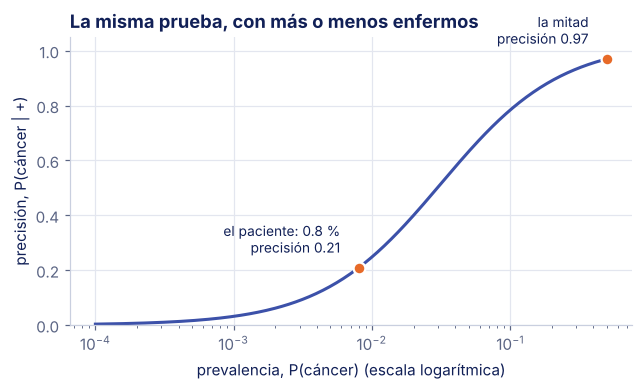

In [6]:
prevalencias = np.logspace(-4, np.log10(0.5), 300)
precisiones = [posterior_cancer(p)[0] for p in prevalencias]

fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.plot(prevalencias, precisiones, color=AZUL_MEDIO, linewidth=2)
for p, texto in [(0.008, "el paciente: 0.8 %"), (0.5, "la mitad")]:
    v = posterior_cancer(p)[0]
    ax.scatter(p, v, s=60, color=NARANJA, edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"{texto}\nprecisión {v:.2f}", (p, v), xytext=(-12, 10), textcoords="offset points", ha="right",
                fontsize=9, color=AZUL_OSCURO)
ax.set_xscale("log")
ax.set_xlabel("prevalencia, P(cáncer) (escala logarítmica)")
ax.set_ylabel("precisión, P(cáncer | +)")
ax.set_ylim(0, 1.05)
ax.set_title("La misma prueba, con más o menos enfermos")
plt.show()

**Lectura.** Con la mitad de la población enferma, la misma prueba tiene una precisión de 0.97; con 0.8 %, de 0.21; con uno de cada 10 000, casi cero. Por eso, cuando las clases están desbalanceadas, la precisión y la sensibilidad se reportan juntas, y la exactitud sola no dice nada (sesión 12).

### Una segunda prueba

Si el paciente se hace una segunda prueba y también sale positiva, la posterior de la primera es la previa de la segunda (lámina 19):

  antes de la prueba: P(cáncer) = 0.0080
          1 positivo: P(cáncer) = 0.2085
         2 positivos: P(cáncer) = 0.8959
         3 positivos: P(cáncer) = 0.9965


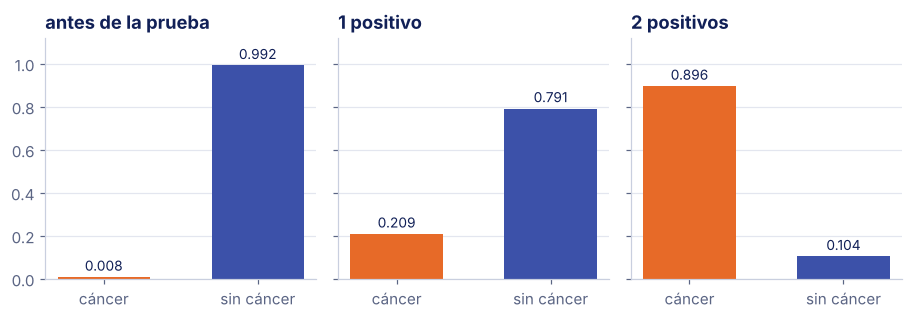

In [7]:
etapas = [("antes de la prueba", PREVALENCIA)]
previa = PREVALENCIA
for k in range(1, 4):
    previa = posterior_cancer(previa)[0]
    etapas.append((f"{k} positivo" + ("s" if k > 1 else ""), previa))
for nombre, p in etapas:
    print(f"{nombre:>20}: P(cáncer) = {p:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.0), sharey=True)
for ax, (nombre, p) in zip(axes, etapas[:3]):
    ax.bar(["cáncer", "sin cáncer"], [p, 1 - p], color=[NARANJA, AZUL_MEDIO], width=0.6)
    for x, v in enumerate([p, 1 - p]):
        ax.text(x, v + 0.03, f"{v:.3f}", ha="center", color=AZUL_OSCURO, fontsize=9)
    ax.set_title(nombre)
    ax.set_ylim(0, 1.12)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Lectura.** Un positivo sube la probabilidad de 0.008 a 0.21; dos, a 0.90; tres, a 0.996. Cada dato concentra la probabilidad, como en la figura de Mitchell de la lámina 18.

La cuenta supone que las dos pruebas son **condicionalmente independientes** dado el diagnóstico (lámina 41): si el paciente tiene cáncer, el resultado de la primera prueba no cambia la probabilidad de que la segunda salga positiva. Si las dos fallaran por la misma causa, por ejemplo la misma interferencia en la muestra, la segunda aportaría mucho menos. Es la suposición de Naive Bayes, y la sección 4 muestra qué pasa cuando no se cumple.

### El clasificador óptimo de Bayes

La hipótesis más probable no siempre da la clasificación más probable (láminas 22 y 23). Con tres hipótesis y sus posteriores:

In [8]:
posteriores = {"h1": 0.4, "h2": 0.3, "h3": 0.3}        # P(h | D)
predicciones = {"h1": "+", "h2": "−", "h3": "−"}       # h(x) para la instancia nueva

h_map = max(posteriores, key=posteriores.get)
votos = {c: sum(p for h, p in posteriores.items() if predicciones[h] == c) for c in ["+", "−"]}
print(f"h_MAP = {h_map}, que clasifica x como {predicciones[h_map]}")
print("Óptimo de Bayes: P(+ | D) =", votos["+"], "| P(− | D) =", votos["−"], "->", max(votos, key=votos.get))

h_MAP = h1, que clasifica x como +
Óptimo de Bayes: P(+ | D) = 0.4 | P(− | D) = 0.6 -> −


**Lectura.** $h_{MAP}$ es $h_1$ y diría «+», pero las otras dos hipótesis, que juntas pesan 0.6, dicen «−». El clasificador óptimo de Bayes promedia las predicciones de todas las hipótesis, ponderadas por su posterior, y ningún otro método que use el mismo espacio de hipótesis y las mismas previas lo supera en promedio (Mitchell, 1997, sección 6.7). Es el «gold standard» de la lámina 8. El costo es que hay que recorrer todas las hipótesis, y por eso en la práctica se usa una aproximación como Naive Bayes.

---

## 2. Naive Bayes a mano con *Play tennis*

Naive Bayes clasifica una instancia $x = \langle a_1, \ldots, a_n \rangle$ con la clase que maximiza

$$v_{NB} = \underset{v_j \in V}{\mathrm{arg\,max}}\; P(v_j) \prod_i P(a_i \mid v_j)$$

y aprender es contar: $P(v_j)$ es la fracción de ejemplos de cada clase, y $P(a_i \mid v_j)$, la fracción de los ejemplos de esa clase que tienen el valor $a_i$ (lámina 27). Lo programamos como una clase con los mismos métodos que los modelos de scikit-learn, `fit`, `predict_proba` y `predict`.

Dos detalles de la clase. Las probabilidades se estiman con el **estimador m** de la lámina 33,

$$\hat P(a_i \mid v_j) = \frac{n_c + m\,p}{n + m},$$

donde $m = 0$ es el conteo crudo y $m = k$, $p = 1/k$ es la corrección de Laplace. Y el producto se calcula sumando logaritmos: con cuatro atributos no hace falta, pero con las miles de palabras de un texto el producto se iría a cero.

In [9]:
class NaiveBayesNominal:
    # Naive_Bayes_Learn y Classify_New_Instance (lámina 27), con el estimador m (lámina 33).
    # m = 0: conteo crudo. m = "laplace": p = 1/k y m = k, con k el número de valores del atributo.

    def __init__(self, m=0, p=None):
        self.m = m
        self.p = p

    def fit(self, X, y):
        self.clases_ = sorted(y.unique(), reverse=True)            # True (Yes) primero
        self.previas_ = {c: (y == c).mean() for c in self.clases_}
        self.valores_ = {a: sorted(X[a].unique()) for a in X.columns}
        self.condicionales_ = {}
        for a, valores in self.valores_.items():
            k = len(valores)
            m = k if self.m == "laplace" else self.m
            p = 1 / k if self.p is None else self.p
            self.condicionales_[a] = {
                (v, c): (((X[a] == v) & (y == c)).sum() + m * p) / ((y == c).sum() + m)
                for v in valores for c in self.clases_}
        return self

    def puntajes(self, x):
        # P(v_j) ∏ P(a_i | v_j) para una instancia x, un diccionario {atributo: valor}
        return {c: self.previas_[c] * math.prod(self.condicionales_[a][(x[a], c)] for a in self.valores_)
                for c in self.clases_}

    def predict_proba(self, X):
        filas = []
        for _, x in X.iterrows():
            with np.errstate(divide="ignore"):                     # log(0) = −inf: una probabilidad de 0
                log_p = np.array([math.log(self.previas_[c]) + sum(np.log(self.condicionales_[a][(x[a], c)])
                                                                     for a in self.valores_) for c in self.clases_])
            log_p -= log_p.max()                                    # así el mayor vale exp(0) = 1 y nada se redondea a 0
            p = np.exp(log_p)
            filas.append(p / p.sum())
        return pd.DataFrame(filas, columns=self.clases_, index=X.index)

    def predict(self, X):
        return self.predict_proba(X).idxmax(axis=1)


ATRIBUTOS = ["Outlook", "Temperature", "Humidity", "Wind"]
X_nom, y_nom = nominal[ATRIBUTOS], nominal["Play"]
nb_crudo = NaiveBayesNominal().fit(X_nom, y_nom)
print("P(v):", {("Yes" if c else "No"): f"{p:.4f}" for c, p in nb_crudo.previas_.items()})

P(v): {'Yes': '0.6429', 'No': '0.3571'}


Las tablas que aprendió, como fracciones de días (lámina 29):

In [10]:
filas = []
for a in ATRIBUTOS:
    for v in nb_crudo.valores_[a]:
        n_si = int(((X_nom[a] == v) & y_nom).sum())
        n_no = int(((X_nom[a] == v) & ~y_nom).sum())
        filas.append({"atributo": a, "valor": v, "Yes": f"{n_si}/9", "No": f"{n_no}/5",
                      "P(a | Yes)": round(nb_crudo.condicionales_[a][(v, True)], 3),
                      "P(a | No)": round(nb_crudo.condicionales_[a][(v, False)], 3)})
pd.DataFrame(filas).set_index(["atributo", "valor"])

Yes   No  P(a | Yes)  P(a | No)
atributo    valor                                    
Outlook     overcast  4/9  0/5       0.444        0.0
            rain      3/9  2/5       0.333        0.4
            sunny     2/9  3/5       0.222        0.6
Temperature cool      3/9  1/5       0.333        0.2
            hot       2/9  2/5       0.222        0.4
            mild      4/9  2/5       0.444        0.4
Humidity    high      3/9  4/5       0.333        0.8
            normal    6/9  1/5       0.667        0.2
Wind        strong    3/9  3/5       0.333        0.6
            weak      6/9  2/5       0.667        0.4

**Lectura.** Cada probabilidad se estima con los 9 o 5 días de su clase. Hay un cero: ninguno de los 4 días nublados es No, así que $\hat P(\text{overcast} \mid \text{No}) = 0/5$. Lo retomamos más abajo.

La instancia de las láminas 30 y 31:

In [11]:
nuevo_dia = {"Outlook": "sunny", "Temperature": "cool", "Humidity": "high", "Wind": "strong"}
puntos = nb_crudo.puntajes(nuevo_dia)
print(f"Yes: 9/14 · 2/9 · 3/9 · 3/9 · 3/9 = {puntos[True]:.4f}")
print(f"No:  5/14 · 3/5 · 1/5 · 4/5 · 3/5 = {puntos[False]:.4f}")
print("v_NB =", "Yes" if puntos[True] > puntos[False] else "No")

proba = nb_crudo.predict_proba(pd.DataFrame([nuevo_dia]))
print(f"\nNormalizado: P(No | x) = {proba[False].iloc[0]:.4f}")

Yes: 9/14 · 2/9 · 3/9 · 3/9 · 3/9 = 0.0053
No:  5/14 · 3/5 · 1/5 · 4/5 · 3/5 = 0.0206
v_NB = No

Normalizado: P(No | x) = 0.7954


**Lectura.** 0.0053 contra 0.0206: Naive Bayes dice No, con 0.795 de probabilidad. Son las cifras de Mitchell (1997, sección 6.9.1). El árbol de la sesión 13 dice lo mismo, por otro camino: Outlook = Sunny y Humidity = High.

### ¿Por qué hace falta la suposición?

Sin la suposición ingenua habría que estimar $P(a_1, \ldots, a_n \mid v_j)$ directamente, una probabilidad para cada combinación de valores (lámina 26):

In [12]:
combinaciones = list(product(*[nb_crudo.valores_[a] for a in ATRIBUTOS]))
vistas = Counter(map(tuple, X_nom.values))
print(f"Combinaciones posibles: {len(combinaciones)}; días: {len(X_nom)}; combinaciones distintas en los datos: {len(vistas)}")
print("¿La instancia aparece en los datos?", tuple(nuevo_dia[a] for a in ATRIBUTOS) in vistas)

# La estimación sin la suposición: la fracción de días de cada clase que son exactamente esa combinación
igual = (X_nom == pd.Series(nuevo_dia)).all(axis=1)
for c, nombre in [(True, "Yes"), (False, "No")]:
    print(f"P(x | {nombre}) estimada sin la suposición: {(igual & (y_nom == c)).sum()}/{(y_nom == c).sum()}")
print("Probabilidades que estima Naive Bayes:", sum(len(v) for v in nb_crudo.valores_.values()) * 2)

Combinaciones posibles: 36; días: 14; combinaciones distintas en los datos: 14
¿La instancia aparece en los datos? False
P(x | Yes) estimada sin la suposición: 0/9
P(x | No) estimada sin la suposición: 0/5
Probabilidades que estima Naive Bayes: 20


**Lectura.** Hay 36 combinaciones y 14 días, todos distintos: cada combinación aparece una vez o ninguna. La instancia no aparece, así que sin la suposición su probabilidad es 0 para las dos clases y el teorema de Bayes da 0/0. Con la suposición bastan 20 probabilidades, cada una estimada con 5 o 9 días. Con $n$ atributos binarios, la conjunta necesita $2^n - 1$ probabilidades por clase y Naive Bayes, $n$: con 30 atributos, más de mil millones contra 30.

### El cero

El cero de la tabla decide solo (lámina 34). Todos los días nublados posibles, sin suavizar y con Laplace:

In [13]:
nb_laplace = NaiveBayesNominal(m="laplace").fit(X_nom, y_nom)
nublados = pd.DataFrame([{"Outlook": "overcast", "Temperature": t, "Humidity": h, "Wind": w}
                         for t, h, w in product(["hot", "mild", "cool"], ["high", "normal"], ["strong", "weak"])])
tabla_nublados = nublados.drop(columns="Outlook").assign(
    **{"P(No), sin suavizar": nb_crudo.predict_proba(nublados)[False].round(3).values,
       "P(No), con Laplace": nb_laplace.predict_proba(nublados)[False].round(3).values})
tabla_nublados.sort_values("P(No), con Laplace", ascending=False).head(4)

,Temperature,Humidity,Wind,"P(No), sin suavizar","P(No), con Laplace"
0,hot,high,strong,0.0,0.436
4,mild,high,strong,0.0,0.316
8,cool,high,strong,0.0,0.278
1,hot,high,weak,0.0,0.249


In [14]:
# El día nublado que más se parece a un No, sin mirar Outlook
sin_outlook = NaiveBayesNominal().fit(X_nom.drop(columns="Outlook"), y_nom)
dia = pd.DataFrame([{"Temperature": "hot", "Humidity": "high", "Wind": "strong"}])
print(f"Hot, high, strong, sin Outlook: P(No) = {sin_outlook.predict_proba(dia)[False].iloc[0]:.3f}")
print(f"La instancia de la lámina 31 con Laplace: P(No | x) = {nb_laplace.predict_proba(pd.DataFrame([nuevo_dia]))[False].iloc[0]:.3f}")

Hot, high, strong, sin Outlook: P(No) = 0.812
La instancia de la lámina 31 con Laplace: P(No | x) = 0.720


**Lectura.** Sin suavizar, todo día nublado sale Yes con probabilidad 1: el cero borra lo que digan los otros tres atributos. En el día nublado, caluroso, húmedo y con viento, esos tres atributos solos dan 0.81 de No; con el cero, 0. Con Laplace, el día queda en 0.44, casi un volado, y la instancia de la lámina 31 baja de 0.795 a 0.720.

### El estimador m

Laplace es un caso particular. Con $m$ ejemplos «virtuales» que se reparten por igual entre los valores, $p = 1/k$:

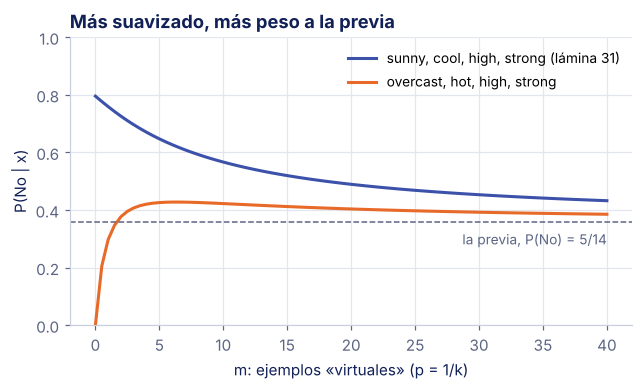

In [15]:
ms = np.linspace(0, 40, 81)
dia_nublado = pd.DataFrame([{"Outlook": "overcast", "Temperature": "hot", "Humidity": "high", "Wind": "strong"}])
curvas = {"sunny, cool, high, strong (lámina 31)": [], "overcast, hot, high, strong": []}
for m in ms:
    modelo = NaiveBayesNominal(m=m).fit(X_nom, y_nom)
    curvas["sunny, cool, high, strong (lámina 31)"].append(modelo.predict_proba(pd.DataFrame([nuevo_dia]))[False].iloc[0])
    curvas["overcast, hot, high, strong"].append(modelo.predict_proba(dia_nublado)[False].iloc[0])

fig, ax = plt.subplots(figsize=(6.6, 3.4))
for (nombre, v), color in zip(curvas.items(), [AZUL_MEDIO, NARANJA]):
    ax.plot(ms, v, color=color, linewidth=2, label=nombre)
ax.axhline(5 / 14, color=GRIS, linewidth=1, linestyle="--")
ax.text(40, 5 / 14 - 0.03, "la previa, P(No) = 5/14", ha="right", va="top", color=GRIS, fontsize=9)
ax.set_xlabel("m: ejemplos «virtuales» (p = 1/k)")
ax.set_ylabel("P(No | x)")
ax.set_ylim(0, 1)
ax.set_title("Más suavizado, más peso a la previa")
ax.legend(loc="upper right", fontsize=9)
plt.show()

**Lectura.** Con $m = 0$ manda el conteo crudo: 0.795 y 0. Basta un ejemplo virtual para que el día nublado deje de ser imposible: con $m = 1$, su probabilidad de No ya es 0.30, y con $m = 2$, 0.38. Al crecer $m$, cada $\hat P(a_i \mid v_j)$ se acerca a $1/k$ en las dos clases, los atributos dejan de distinguir y las dos curvas bajan hacia la previa, 5/14 = 0.357: con $m = 40$ ya van en 0.43 y 0.39. Con 14 días, unos cuantos ejemplos virtuales pesan tanto como los reales; con miles de ejemplos, casi nada.

---

## 3. Los mismos días en scikit-learn

scikit-learn tiene una clase de Naive Bayes para cada tipo de atributo (lámina 36):

| Clase | Atributos | Cómo estima $P(a_i \mid v_j)$ |
|---|---|---|
| `CategoricalNB` | nominales, codificados como 0, 1, …, k − 1 | conteos con suavizado `alpha` |
| `GaussianNB` | continuos | una normal por clase |
| `MultinomialNB` | conteos, como las palabras de un texto | frecuencias relativas con suavizado `alpha` |
| `BernoulliNB` | binarios: presente o ausente | proporciones con suavizado `alpha` |

En las tres con `alpha`, `alpha = 1` es la corrección de Laplace y `alpha` < 1, la de Lidstone. Todas suman logaritmos, como nuestra clase.

### Atributos nominales: `CategoricalNB`

In [16]:
from sklearn.naive_bayes import BernoulliNB, CategoricalNB, GaussianNB, MultinomialNB
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

codificador = OrdinalEncoder().fit(X_nom)
X_cod = codificador.transform(X_nom)
x_cod = codificador.transform(pd.DataFrame([nuevo_dia]))
print("Códigos de Outlook:", dict(enumerate(codificador.categories_[0])))

for alpha in [1e-10, 1.0]:
    cnb = CategoricalNB(alpha=alpha).fit(X_cod, y_nom)
    p_no = cnb.predict_proba(x_cod)[0][list(cnb.classes_).index(False)]
    print(f"CategoricalNB, alpha = {alpha:g}: P(No | x) = {p_no:.4f}")
print(f"Nuestra clase:  crudo {nb_crudo.predict_proba(pd.DataFrame([nuevo_dia]))[False].iloc[0]:.4f}, "
      f"Laplace {nb_laplace.predict_proba(pd.DataFrame([nuevo_dia]))[False].iloc[0]:.4f}")

Códigos de Outlook: {0: 'overcast', 1: 'rain', 2: 'sunny'}
CategoricalNB, alpha = 1e-10: P(No | x) = 0.7954
CategoricalNB, alpha = 1: P(No | x) = 0.7201
Nuestra clase:  crudo 0.7954, Laplace 0.7201


**Lectura.** `CategoricalNB` da lo mismo que nuestra clase: 0.795 con `alpha` casi 0 y 0.720 con el `alpha = 1` por omisión. Por omisión, scikit-learn suaviza.

Aquí `OrdinalEncoder` **sí se vale**, al revés que en los árboles (sesión 13): `CategoricalNB` usa los códigos solo como etiquetas para contar, y le da igual que overcast sea 0 y sunny 2. Lo que falla es darle esos atributos al modelo equivocado.

### Una instancia, cuatro respuestas

La misma instancia con cuatro combinaciones de modelo y codificación (lámina 37):

In [17]:
onehot = OneHotEncoder(sparse_output=False).fit(X_nom)
X_oh, x_oh = onehot.transform(X_nom), onehot.transform(pd.DataFrame([nuevo_dia]))


def p_no(modelo, X_, x_):
    modelo.fit(X_, y_nom)
    return modelo.predict_proba(x_)[0][list(modelo.classes_).index(False)]


respuestas = pd.Series({
    "CategoricalNB + OrdinalEncoder": p_no(CategoricalNB(), X_cod, x_cod),
    "BernoulliNB + one-hot": p_no(BernoulliNB(), X_oh, x_oh),
    "GaussianNB + OrdinalEncoder": p_no(GaussianNB(), X_cod, x_cod),
    "GaussianNB + one-hot": p_no(GaussianNB(), X_oh, x_oh),
}, name="P(No | x)")

# GaussianNB con códigos: cada orden posible de los códigos da otra respuesta
otras = []
for orden in product(*[permutations(v) for v in codificador.categories_]):
    cod = OrdinalEncoder(categories=[list(o) for o in orden]).fit(X_nom)
    otras.append(p_no(GaussianNB(), cod.transform(X_nom), cod.transform(pd.DataFrame([nuevo_dia]))))
print(f"GaussianNB + OrdinalEncoder, con los {len(otras)} órdenes posibles de los códigos: de {min(otras):.3f} a {max(otras):.3f}")
respuestas.round(3).to_frame()

GaussianNB + OrdinalEncoder, con los 144 órdenes posibles de los códigos: de 0.681 a 0.912


,P(No | x)
CategoricalNB + OrdinalEncoder,0.720
BernoulliNB + one-hot,0.910
GaussianNB + OrdinalEncoder,0.891
GaussianNB + one-hot,1.000


**Lectura.** Solo la primera es correcta. `BernoulliNB` con *one-hot* da 0.910: trata cada columna como un atributo independiente, y las columnas de un mismo atributo no lo son, porque si el día es sunny no puede ser rain. `GaussianNB` trata los códigos como números con una media y una varianza, y su respuesta cambia con el orden de los códigos: de 0.681 a 0.912. Con *one-hot*, `GaussianNB` llega a 1.000: le ajusta una normal a columnas de ceros y unos.

### Atributos continuos: una normal por clase

En `weather.numeric.csv`, la temperatura y la humedad son números. Naive Bayes gaussiano supone que, dentro de cada clase, cada atributo sigue una normal con su propia media y desviación estándar (lámina 35):

$$f(x \mid v_j) = \frac{1}{\sqrt{2\pi}\,\sigma_j} \exp\left(-\frac{(x - \mu_j)^2}{2\sigma_j^2}\right)$$

Un día sunny, de 66 °F, con humedad de 90 % y viento strong. Es el ejemplo del libro de Weka (Witten *et al.*, 2016, sección 4.2). Los atributos nominales se cuentan como antes, y los numéricos entran con su densidad:

In [18]:
x_num = {"Outlook": "sunny", "Temperature": 66, "Humidity": 90, "Wind": "strong"}


def normal(x, media, de):
    return math.exp(-(x - media) ** 2 / (2 * de ** 2)) / (math.sqrt(2 * math.pi) * de)


def puntaje_mixto(x, ddof):
    # Conteos para Outlook y Wind; una normal por clase para Temperature y Humidity.
    # ddof = 1 divide la varianza entre n − 1 (la desviación estándar muestral); ddof = 0, entre n.
    puntos, detalle = {}, []
    for c in [True, False]:
        dias = numerico[numerico["Play"] == c]
        p = len(dias) / len(numerico)
        for a in ["Outlook", "Wind"]:
            p *= (dias[a] == x[a]).mean()
        for a in ["Temperature", "Humidity"]:
            media, de = dias[a].mean(), dias[a].std(ddof=ddof)
            f = normal(x[a], media, de)
            p *= f
            detalle.append({"clase": "Yes" if c else "No", "atributo": a, "media": media, "desv. est.": de, "f(x | v)": f})
        puntos[c] = p
    return puntos, pd.DataFrame(detalle)


puntos, detalle = puntaje_mixto(x_num, ddof=1)
print(f"Yes: {puntos[True]:.6f}   No: {puntos[False]:.6f}   P(No | x) = {puntos[False] / sum(puntos.values()):.3f}")
detalle.round(4)

Yes: 0.000036   No: 0.000136   P(No | x) = 0.792


,clase,atributo,media,desv. est.,f(x | v)
0,Yes,Temperature,73.0000,6.1644,0.0340
1,Yes,Humidity,79.1111,10.2157,0.0221
2,No,Temperature,74.6000,7.8930,0.0279
3,No,Humidity,86.2000,9.7314,0.0380


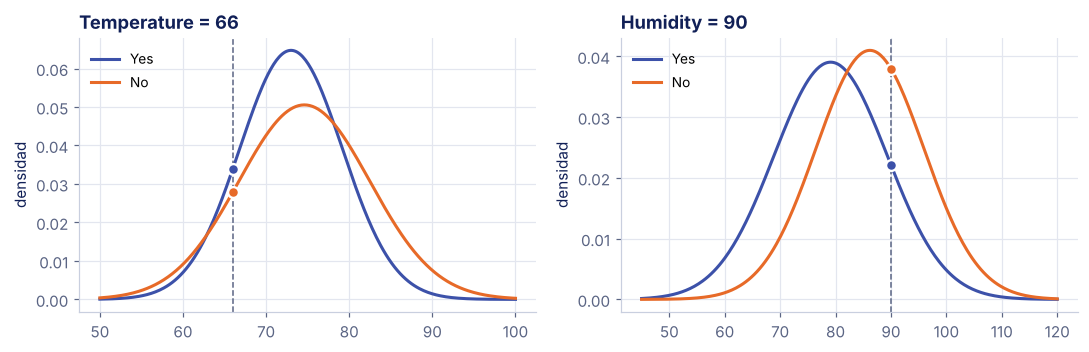

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, (atributo, valor, rango) in zip(axes, [("Temperature", 66, (50, 100)), ("Humidity", 90, (45, 120))]):
    xs = np.linspace(*rango, 300)
    for c, color, nombre in [(True, AZUL_MEDIO, "Yes"), (False, NARANJA, "No")]:
        fila = detalle[(detalle["clase"] == nombre) & (detalle["atributo"] == atributo)].iloc[0]
        ax.plot(xs, [normal(v, fila["media"], fila["desv. est."]) for v in xs], color=color, linewidth=2, label=nombre)
        ax.scatter(valor, fila["f(x | v)"], s=50, color=color, edgecolor="white", linewidth=1.5, zorder=3)
    ax.axvline(valor, color=GRIS, linewidth=1, linestyle="--")
    ax.set_title(f"{atributo} = {valor}")
    ax.set_ylabel("densidad")
    ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

**Lectura.** El día sale No con probabilidad 0.79. La temperatura casi no distingue: las dos medias, 73.0 y 74.6 °F, están juntas. La humedad sí: 90 % está más cerca de la media de los días No, 86.2, que de la de los Yes, 79.1. Las densidades no son probabilidades y pueden pasar de 1; lo que importa es su cociente entre clases.

`GaussianNB` estima la varianza dividiendo entre $n$, no entre $n - 1$, y le suma un poco de suavizado (`var_smoothing`). scikit-learn tampoco tiene una clase para atributos de los dos tipos, pero como todo es una suma de logaritmos, basta sumar lo que aporta cada modelo y restar una vez la previa, que los dos cuentan:

In [20]:
nominales, numericos = ["Outlook", "Wind"], ["Temperature", "Humidity"]
cod2 = OrdinalEncoder().fit(numerico[nominales])
cnb = CategoricalNB(alpha=1e-10).fit(cod2.transform(numerico[nominales]), numerico["Play"])
gnb = GaussianNB().fit(numerico[numericos], numerico["Play"])

xdf = pd.DataFrame([x_num])
log_conjunta = (cnb.predict_joint_log_proba(cod2.transform(xdf[nominales]))
                + gnb.predict_joint_log_proba(xdf[numericos]) - np.log(gnb.class_prior_))
proba = np.exp(log_conjunta - log_conjunta.max())
proba /= proba.sum()
print(f"scikit-learn, CategoricalNB + GaussianNB: P(No | x) = {proba[0][list(gnb.classes_).index(False)]:.3f}")
puntos0, _ = puntaje_mixto(x_num, ddof=0)
print(f"A mano, con la varianza entre n:           P(No | x) = {puntos0[False] / sum(puntos0.values()):.3f}")

scikit-learn, CategoricalNB + GaussianNB: P(No | x) = 0.806
A mano, con la varianza entre n:           P(No | x) = 0.806


**Lectura.** Con la varianza entre $n$, la cuenta a mano y scikit-learn coinciden: 0.806, contra 0.792 con $n - 1$. Es el mismo tipo de diferencia que los umbrales de J48 y de scikit-learn en la sesión 13: dos convenciones razonables, dos números distintos.

### Códigos como números

Una forma tentadora de usar `weather.numeric.csv` es convertir Outlook y Wind en números con `LabelEncoder` y darle todo a `GaussianNB`. Así lo hacía el notebook de la edición anterior. Para un día sunny, de 85 °F, con 65 % de humedad y viento strong:

In [21]:
viento = numerico["Wind"].map({"strong": 0, "weak": 1})
codigos = {"alfabético, como LabelEncoder": {"overcast": 0, "rain": 1, "sunny": 2},
           "sunny = 0, overcast = 1, rain = 2": {"sunny": 0, "overcast": 1, "rain": 2},
           "rain = 0, sunny = 1, overcast = 2": {"rain": 0, "sunny": 1, "overcast": 2}}
filas = {}
for nombre, cod in codigos.items():
    X_lab = pd.DataFrame({"Outlook": numerico["Outlook"].map(cod), "Temperature": numerico["Temperature"],
                          "Humidity": numerico["Humidity"], "Wind": viento})
    gnb_lab = GaussianNB().fit(X_lab, numerico["Play"])
    x_lab = pd.DataFrame([[cod["sunny"], 85, 65, 0]], columns=X_lab.columns)
    filas[nombre] = gnb_lab.predict_proba(x_lab)[0][list(gnb_lab.classes_).index(False)]

x_viejo = {"Outlook": "sunny", "Temperature": 85, "Humidity": 65, "Wind": "strong"}
p_viejo, _ = puntaje_mixto(x_viejo, ddof=0)
filas["el modelo mixto de arriba"] = p_viejo[False] / sum(p_viejo.values())
pd.Series(filas, name="P(No | x)").round(3).to_frame()

,P(No | x)
"alfabético, como LabelEncoder",0.611
"sunny = 0, overcast = 1, rain = 2",0.406
"rain = 0, sunny = 1, overcast = 2",0.344
el modelo mixto de arriba,0.513


**Lectura.** Con los códigos alfabéticos, `GaussianNB` dice No (0.611); con otro orden, Yes (0.406 o 0.344). Los mismos datos, tres respuestas, y ninguna es la del modelo correcto, que da 0.513: casi un volado, porque el día es soleado y con viento, como los días No, pero también caluroso y seco. Es la trampa de `LabelEncoder` de la sesión 13 en otro modelo.

---

## 4. El vino: la suposición no se cumple

Volvemos al vino de 3 clases de la sesión 12 con el protocolo del notebook 13: 20 % para prueba con los duplicados del mismo lado, validación cruzada agrupada dentro del entrenamiento y la prueba una sola vez. El notebook 12 usó `GaussianNB` como caja negra; ahora sabemos qué supone.

In [22]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import KBinsDiscretizer, PowerTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

vinos = pd.read_csv("datos/vinos-3clases.csv")
# vinos = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/vinos-3clases.csv")

X = vinos.drop(columns="calidad")
y = vinos["calidad"]
grupos = pd.util.hash_pandas_object(vinos, index=False)      # filas idénticas, mismo grupo (notebook 12)

i_entrena, i_prueba = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y, grupos))
X_entrena, X_prueba = X.iloc[i_entrena], X.iloc[i_prueba]
y_entrena, y_prueba = y.iloc[i_entrena], y.iloc[i_prueba]
g_entrena = grupos.iloc[i_entrena]
pliegues = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f"Entrenamiento: {len(i_entrena)} vinos; prueba: {len(i_prueba)}")

Entrenamiento: 1279 vinos; prueba: 320


**Lectura.** Es la misma partición del notebook 13: 1279 vinos para entrenar y 320 para la prueba.

### ¿Son independientes los atributos dentro de cada clase?

La suposición dice que, conocida la clase, un atributo no informa sobre otro. Una forma rápida de revisarla es la correlación entre atributos dentro de cada clase, con los vinos de entrenamiento:

In [23]:
pares = {}
for c in CLASES:
    r = X_entrena[y_entrena == c].corr()
    for i, a in enumerate(r.columns):
        for b in r.columns[i + 1:]:
            pares.setdefault(f"{a} · {b}", {})[c] = r.loc[a, b]
pares = pd.DataFrame(pares).T[CLASES]
pares[(pares.abs() > 0.6).any(axis=1)].round(2).sort_values("alta")

,baja,media,alta
fixed acidity · pH,-0.63,-0.72,-0.78
citric acid · pH,-0.50,-0.55,-0.74
free sulfur dioxide · total sulfur dioxide,0.69,0.67,0.65
fixed acidity · citric acid,0.62,0.69,0.73
fixed acidity · density,0.69,0.70,0.78


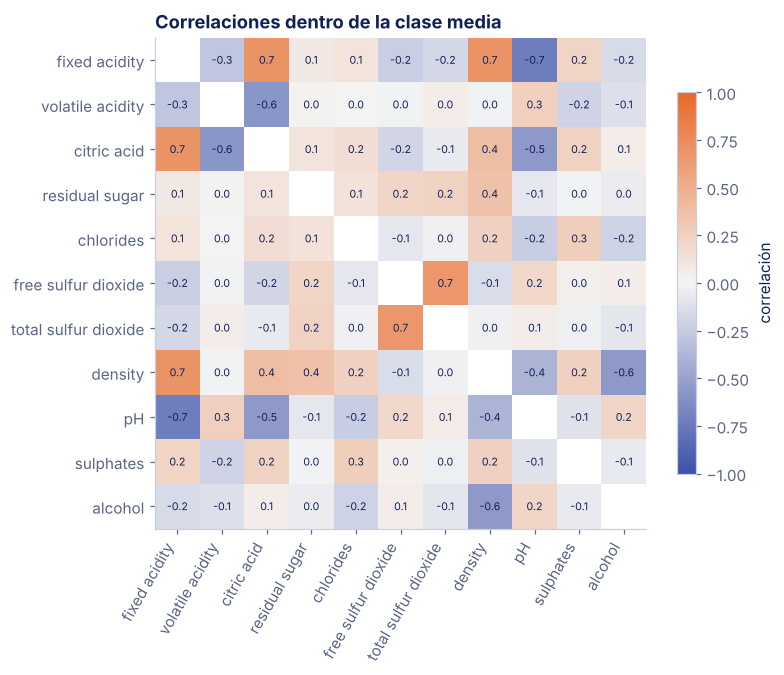

In [24]:
r_media = X_entrena[y_entrena == "media"].corr()
divergente = LinearSegmentedColormap.from_list("azul_naranja", [AZUL_MEDIO, "#F4F4F4", NARANJA])
sin_diagonal = r_media.mask(np.eye(len(r_media), dtype=bool))      # la correlación de un atributo consigo mismo no dice nada

fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(sin_diagonal, cmap=divergente, vmin=-1, vmax=1)
ax.set_xticks(range(len(r_media)), r_media.columns, rotation=60, ha="right")
ax.set_yticks(range(len(r_media)), r_media.columns)
for i in range(len(r_media)):
    for j in range(len(r_media)):
        if i != j:
            ax.text(j, i, f"{r_media.iloc[i, j]:.1f}".replace("-0.0", "0.0"), ha="center", va="center", fontsize=7, color=AZUL_OSCURO)
ax.grid(False)
ax.set_title("Correlaciones dentro de la clase media")
fig.colorbar(im, ax=ax, shrink=0.75, label="correlación")
plt.show()

**Lectura.** No se cumple. Dentro de cada clase, la acidez fija tiene correlaciones de 0.69 a 0.78 con la densidad y de −0.63 a −0.78 con el pH, y el SO₂ libre y el total, de 0.65 a 0.69. Con la clase conocida, saber la acidez fija de un vino sí informa sobre su densidad. Naive Bayes va a contar esa información dos veces.

### Clasifica bien, estima mal

Lo comparamos con la logística y con el árbol elegido en el notebook 13, con las mismas particiones. Además del F1 macro, medimos dos cosas de sus probabilidades. La **confianza media** es el promedio de la probabilidad que el modelo le da a la clase que predice; si el modelo está bien calibrado, debería parecerse a su tasa de aciertos. El **log-loss** es la entropía cruzada de la sesión 11: castiga una probabilidad alta en la clase equivocada, y menor es mejor.

In [25]:
def evaluar(modelo):
    r = cross_validate(modelo, X_entrena, y_entrena, groups=g_entrena, cv=pliegues, scoring="f1_macro")
    modelo.fit(X_entrena, y_entrena)
    P = modelo.predict_proba(X_prueba)
    prediccion = modelo.classes_[P.argmax(axis=1)]
    return {"F1 macro, validación": r["test_score"].mean(), "desv. est.": r["test_score"].std(),
            "F1 macro, prueba": f1_score(y_prueba, prediccion, average="macro"),
            "aciertos": accuracy_score(y_prueba, prediccion), "confianza media": P.max(axis=1).mean(),
            "log-loss": log_loss(y_prueba, P, labels=modelo.classes_),
            "% con confianza > 0.99": 100 * (P.max(axis=1) > 0.99).mean()}


modelos = {
    "Naive Bayes": GaussianNB(),
    "regresión logística": make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)),
    "árbol elegido (notebook 13)": DecisionTreeClassifier(random_state=0, max_depth=6, min_samples_leaf=5),
}
comparacion = pd.DataFrame({nombre: evaluar(m) for nombre, m in modelos.items()}).T
comparacion.round(3)

,"F1 macro, validación",desv. est.,"F1 macro, prueba",aciertos,confianza media,log-loss,% con confianza > 0.99
Naive Bayes,0.579,0.044,0.596,0.612,0.689,0.955,5.625
regresión logística,0.562,0.022,0.573,0.619,0.624,0.754,0.000
árbol elegido (notebook 13),0.584,0.022,0.551,0.581,0.759,3.133,18.750


**Lectura.** En F1, Naive Bayes empata con los otros dos: 0.579 en validación y 0.596 en prueba, contra 0.562 y 0.573 de la logística y 0.584 y 0.551 del árbol. Las diferencias son del tamaño de la desviación entre pliegues, de 0.02 a 0.04. La suposición falla y el modelo clasifica igual de bien: no necesita que sus probabilidades sean correctas, solo que la clase correcta quede arriba (lámina 32; Domingos y Pazzani, 1997).

Pero sus probabilidades son peores. Confía en 0.69 cuando acierta en 0.61, y 5.6 % de sus predicciones pasan de 0.99. La logística confía en 0.62 y acierta en 0.62: se ajusta maximizando la verosimilitud, que es minimizar justamente el log-loss (lámina 21). El árbol podado es el peor calibrado: confía en 0.76 y acierta en 0.58, y su log-loss es altísimo porque algunas de sus hojas dan probabilidad 0 a la clase correcta. La guía de scikit-learn lo dice de Naive Bayes: es un buen clasificador y un mal estimador de probabilidades.

### Confianza contra aciertos

Agrupamos los vinos de prueba por la confianza del modelo y, en cada grupo, comparamos la confianza promedio con la fracción de aciertos. En un modelo bien calibrado, los puntos caen sobre la diagonal (Niculescu-Mizil y Caruana, 2005):

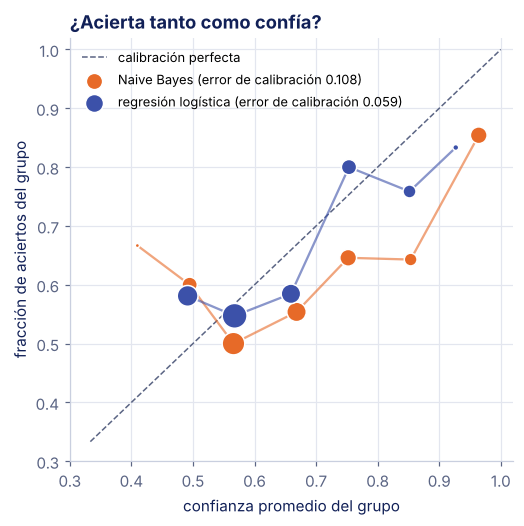

In [26]:
def confiabilidad(modelo, cortes=np.linspace(1 / 3, 1, 8)):
    modelo.fit(X_entrena, y_entrena)
    P = modelo.predict_proba(X_prueba)
    confianza = P.max(axis=1)
    acierto = modelo.classes_[P.argmax(axis=1)] == y_prueba.to_numpy()
    grupo = np.clip(np.digitize(confianza, cortes) - 1, 0, len(cortes) - 2)
    t = pd.DataFrame({"grupo": grupo, "confianza": confianza, "acierto": acierto}).groupby("grupo").agg(
        n=("acierto", "size"), confianza=("confianza", "mean"), aciertos=("acierto", "mean"))
    ece = (t["n"] * (t["confianza"] - t["aciertos"]).abs()).sum() / len(confianza)
    return t, ece


fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([1 / 3, 1], [1 / 3, 1], color=GRIS, linewidth=1, linestyle="--", label="calibración perfecta")
for nombre, color in [("Naive Bayes", NARANJA), ("regresión logística", AZUL_MEDIO)]:
    t, ece = confiabilidad(modelos[nombre])
    ax.plot(t["confianza"], t["aciertos"], color=color, linewidth=1.5, alpha=0.6)
    ax.scatter(t["confianza"], t["aciertos"], s=t["n"] * 2.5, color=color, edgecolor="white", linewidth=1, zorder=3,
               label=f"{nombre} (error de calibración {ece:.3f})")
ax.set_xlabel("confianza promedio del grupo")
ax.set_ylabel("fracción de aciertos del grupo")
ax.set_xlim(0.3, 1.02); ax.set_ylim(0.3, 1.02)
ax.set_title("¿Acierta tanto como confía?")
ax.legend(loc="upper left", fontsize=8.5)
plt.show()

**Lectura.** Los puntos de Naive Bayes caen por debajo de la diagonal: en casi todos los grupos confía más de lo que acierta. El grupo más confiado, con 48 vinos, promedia 0.96 de confianza y acierta en 0.85. El área de cada punto es el número de vinos del grupo. El error de calibración esperado, el promedio de la distancia a la diagonal ponderado por esos números, es 0.108 para Naive Bayes y 0.059 para la logística. Para elegir un umbral con costos, como el de un banco que decide a quién llamar, hacen falta probabilidades calibradas; las de Naive Bayes habría que recalibrarlas primero (`CalibratedClassifierCV` en scikit-learn).

### La misma evidencia, contada varias veces

La prueba más directa de la suposición: agregamos copias del alcohol como atributos nuevos. No aportan información, pero Naive Bayes las cree independientes (lámina 39):

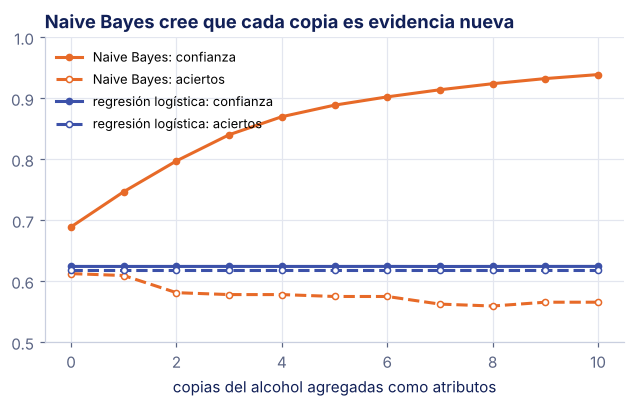

confianza media  aciertos  log-loss  \
copias modelo                                                     
0      Naive Bayes                    0.689     0.612     0.955   
       regresión logística            0.624     0.619     0.754   
1      Naive Bayes                    0.747     0.609     1.036   
       regresión logística            0.624     0.619     0.754   
5      Naive Bayes                    0.889     0.575     1.890   
       regresión logística            0.624     0.619     0.754   
10     Naive Bayes                    0.939     0.566     3.194   
       regresión logística            0.624     0.619     0.754   

                            % con confianza > 0.99  
copias modelo                                       
0      Naive Bayes                           5.625  
       regresión logística                   0.000  
1      Naive Bayes                           7.500  
       regresión logística                   0.000  
5      Naive Bayes                          26.875  
       regresión logística                   0.000  
10     Naive Bayes                          63.125  
       regresión logística                   0.000

In [27]:
filas = []
for k in range(0, 11):
    A_entrena = X_entrena.assign(**{f"alcohol_{i}": X_entrena["alcohol"] for i in range(k)})
    A_prueba = X_prueba.assign(**{f"alcohol_{i}": X_prueba["alcohol"] for i in range(k)})
    for nombre in ["Naive Bayes", "regresión logística"]:
        m = clone(modelos[nombre]).fit(A_entrena, y_entrena)
        P = m.predict_proba(A_prueba)
        filas.append({"copias": k, "modelo": nombre, "confianza media": P.max(axis=1).mean(),
                      "aciertos": accuracy_score(y_prueba, m.classes_[P.argmax(axis=1)]),
                      "log-loss": log_loss(y_prueba, P, labels=m.classes_),
                      "% con confianza > 0.99": 100 * (P.max(axis=1) > 0.99).mean()})
copias = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(6.8, 3.6))
for nombre, color in [("Naive Bayes", NARANJA), ("regresión logística", AZUL_MEDIO)]:
    t = copias[copias["modelo"] == nombre]
    ax.plot(t["copias"], t["confianza media"], color=color, linewidth=2, marker="o", markersize=4, label=f"{nombre}: confianza")
    ax.plot(t["copias"], t["aciertos"], color=color, linewidth=2, linestyle="--", marker="o", markersize=4,
            markerfacecolor="white", label=f"{nombre}: aciertos")
ax.set_xlabel("copias del alcohol agregadas como atributos")
ax.set_ylim(0.5, 1)
ax.set_title("Naive Bayes cree que cada copia es evidencia nueva")
ax.legend(loc="upper left", fontsize=8.5)
plt.show()
copias[copias["copias"].isin([0, 1, 5, 10])].set_index(["copias", "modelo"]).round(3)

**Lectura.** Con cada copia, Naive Bayes multiplica otra vez la misma evidencia. Con 10 copias, su confianza media sube de 0.69 a 0.94, sus aciertos bajan de 0.61 a 0.57, su log-loss pasa de 0.955 a 3.194 y 63 % de sus predicciones pasan de 0.99. Es la sutileza 1 en estado puro: las posteriores se acercan a 0 o a 1 sin razón (lámina 32). A la logística no le pasa nada: reparte el coeficiente del alcohol entre las copias y sus predicciones no cambian. Los atributos muy correlacionados del vino, como la acidez fija y la densidad, hacen lo mismo en menor grado.

### ¿Qué se puede ajustar?

Naive Bayes casi no tiene hiperparámetros. El de `GaussianNB` es `var_smoothing`, una fracción de la mayor varianza que se le suma a todas para que ninguna sea casi cero. Lo elegimos con el protocolo de siempre:

In [28]:
busqueda = GridSearchCV(GaussianNB(), {"var_smoothing": np.logspace(-9, 0, 10)}, cv=pliegues, scoring="f1_macro")
busqueda.fit(X_entrena, y_entrena, groups=g_entrena)
resultados_vs = pd.DataFrame(busqueda.cv_results_)
pd.DataFrame({"var_smoothing": resultados_vs["param_var_smoothing"].map(lambda v: f"{v:.0e}"),
              "F1 macro, validación": resultados_vs["mean_test_score"].round(3),
              "desv. est.": resultados_vs["std_test_score"].round(3)})

,var_smoothing,"F1 macro, validación",desv. est.
0,1e-09,0.579,0.044
1,1e-08,0.581,0.046
2,1e-07,0.583,0.041
3,1e-06,0.581,0.040
4,1e-05,0.553,0.048
5,1e-04,0.506,0.029
6,1e-03,0.423,0.060
7,1e-02,0.354,0.025
8,1e-01,0.345,0.021
9,1e+00,0.358,0.019


**Lectura.** Da lo mismo hasta $10^{-6}$ (0.579 a 0.583, dentro del ruido) y luego se desploma: al sumarle demasiado a las varianzas, las normales se aplanan y dejan de distinguir. No hay nada que ganar aquí.

Lo que sí se puede elegir es la **representación**. Dos alternativas que acercan los datos a lo que el modelo supone: transformar cada atributo para que se parezca a una normal (Yeo-Johnson, con `PowerTransformer`), o discretizarlo en intervalos con el mismo número de vinos y usar `CategoricalNB`, como con *Play tennis*. Con muchos intervalos, los atributos con valores repetidos, como el ácido cítrico, que vale 0 en muchos vinos, se quedan con menos: scikit-learn junta los intervalos vacíos y avisa; aquí silenciamos ese aviso.

In [29]:
discretizado = make_pipeline(KBinsDiscretizer(encode="ordinal", strategy="quantile", quantile_method="averaged_inverted_cdf"),
                             CategoricalNB())
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Bins whose width are too small")    # intervalos vacíos que se juntan
    busqueda_bins = GridSearchCV(discretizado, {"kbinsdiscretizer__n_bins": [2, 3, 4, 5, 6, 8, 10, 15, 20]}, cv=pliegues,
                                 scoring="f1_macro").fit(X_entrena, y_entrena, groups=g_entrena)
print("Intervalos por atributo:", busqueda_bins.best_params_["kbinsdiscretizer__n_bins"],
      f"(F1 macro en validación {busqueda_bins.best_score_:.3f})")

representaciones = {
    "GaussianNB": GaussianNB(),
    "Yeo-Johnson + GaussianNB": make_pipeline(PowerTransformer(), GaussianNB()),
    f"{busqueda_bins.best_params_['kbinsdiscretizer__n_bins']} intervalos + CategoricalNB": busqueda_bins.best_estimator_,
}
validacion = {nombre: cross_validate(m, X_entrena, y_entrena, groups=g_entrena, cv=pliegues, scoring="f1_macro")["test_score"]
              for nombre, m in representaciones.items()}
pd.DataFrame({"F1 macro, validación": {n: v.mean() for n, v in validacion.items()},
              "desv. est.": {n: v.std() for n, v in validacion.items()}}).round(3)

Intervalos por atributo: 5 (F1 macro en validación 0.565)


,"F1 macro, validación",desv. est.
GaussianNB,0.579,0.044
Yeo-Johnson + GaussianNB,0.568,0.029
5 intervalos + CategoricalNB,0.565,0.015


**Lectura.** Las tres quedan entre 0.565 y 0.579, con desviaciones de 0.015 a 0.044: no se distinguen. La validación elige `GaussianNB` sin transformar, y es el que medimos en prueba, una sola vez: 0.596. Si miráramos la prueba de las tres antes de elegir, alguna saldría mejor por azar, y ese número ya no estimaría nada (notebook 13).

### La tabla de la unidad

Los tres modelos que ya abrimos, con el mismo protocolo:

In [30]:
tabla_unidad = comparacion[["F1 macro, validación", "F1 macro, prueba", "aciertos", "confianza media", "log-loss"]]
tabla_unidad.round(3)

,"F1 macro, validación","F1 macro, prueba",aciertos,confianza media,log-loss
Naive Bayes,0.579,0.596,0.612,0.689,0.955
regresión logística,0.562,0.573,0.619,0.624,0.754
árbol elegido (notebook 13),0.584,0.551,0.581,0.759,3.133


**Lectura.** Los tres están entre 0.55 y 0.60 de F1 macro en prueba, y sus diferencias no son mayores que el ruido entre pliegues. Lo que sí los separa es la calidad de sus probabilidades: la logística es la única bien calibrada.

---

Las sesiones 15 y 16 abren las dos cajas negras que faltan: el vecino más cercano y las máquinas de soporte vectorial. Cada una agrega su fila a esta tabla con el mismo protocolo, que es el que pedirá la práctica de la unidad. La sección 1 es también la base de la Tarea 4: con pocos positivos, la exactitud engaña y la precisión cae.

---

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de Claude (Anthropic) para estructurar el contenido a partir de las diapositivas de la sesión, redactar el texto explicativo y preparar los ejemplos. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.

### Referencias

- Mitchell, T. M. (1997). *Machine Learning*, capítulo 6: Bayesian Learning. McGraw-Hill.
- Domingos, P., & Pazzani, M. (1997). On the optimality of the simple Bayesian classifier under zero-one loss. *Machine Learning*, 29(2-3), 103-130.
- Gigerenzer, G., & Hoffrage, U. (1995). How to improve Bayesian reasoning without instruction: Frequency formats. *Psychological Review*, 102(4), 684-704.
- Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning*, 625-632.
- Witten, I. H., Frank, E., Hall, M. A., & Pal, C. J. (2016). *Data Mining: Practical Machine Learning Tools and Techniques*, 4a ed. Morgan Kaufmann. (El libro de Weka; la sección 4.2 trae el ejemplo de los atributos numéricos.)
- VanderPlas, J. (2022). *Python Data Science Handbook*, 2a ed. O'Reilly. [Capítulo 41: In Depth: Naive Bayes Classification](https://jakevdp.github.io/PythonDataScienceHandbook/05.05-naive-bayes.html)
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, 47(4), 547-553.
- [scikit-learn: Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html) · [CategoricalNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.CategoricalNB.html) · [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html) · [Calibración de probabilidades](https://scikit-learn.org/stable/modules/calibration.html)